# Demostración de los modelos seleccionados

**Sistema final:** RF-DETR Nano **E5-v2** (detección acústica) + **Swin-T** (31 clases, incluida `OTHER_SPECIES`).

Este notebook utiliza el dataset público en Kaggle.

**Tres pruebas:** (1) detector individual, (2) clasificador individual y (3) sistema integrado detector -> clasificador.

## Instalación de dependencias

In [17]:
%pip -q install "rfdetr==1.12.0" "kagglehub==1.0.3" soundfile scipy pandas matplotlib pillow torchvision

## Fuentes públicas y comprobación de artefactos


In [18]:
from pathlib import Path
import sys
import json

import kagglehub
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from PIL import Image
from IPython.display import display

DATASET_MODELOS = "santiagocorrea802/modelos-deep-learning-seales-acsticas"
DATASET_AUDIO = "santiagocorrea802/dataset-proyecto"
DATASET_CLASIFICADOR = "santiagocorrea802/clasificador-aves-espectrogramas-v1/versions/1"

# Descargamos solo el paquete de modelos (sin copiar el corpus completo)
BUNDLE = Path(kagglehub.dataset_download(DATASET_MODELOS))
ESENCIALES = ("modelo_detector.pth", "modelo_clasificador.pth", "config_detector.json", "class_mapping.json", "preprocessing_config.json", "protocolo.json", "requirements.txt", "sistema_aves.py",)
faltantes = [nombre for nombre in ESENCIALES if not (BUNDLE / nombre).is_file()]
if faltantes:
    raise FileNotFoundError(f"Archivos faltantes en {BUNDLE}: {faltantes}. Publica el contenido de Sistema_Aves_v1 en la raíz del dataset.")

print("Paquete:", BUNDLE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No disponible; se usará CPU")
for nombre in ESENCIALES:
    ruta = BUNDLE / nombre
    print(f"{nombre}: {ruta.stat().st_size / (1024**2):.2f} MiB")

Using Colab cache for faster access to the 'modelos-deep-learning-seales-acsticas' dataset.
Paquete: /kaggle/input/modelos-deep-learning-seales-acsticas
GPU: Tesla T4
modelo_detector.pth: 115.30 MiB
modelo_clasificador.pth: 105.35 MiB
config_detector.json: 0.00 MiB
class_mapping.json: 0.00 MiB
preprocessing_config.json: 0.00 MiB
protocolo.json: 0.00 MiB
requirements.txt: 0.00 MiB
sistema_aves.py: 0.01 MiB


##Carga de los modelos seleccionados


In [19]:
if str(BUNDLE) not in sys.path:
    sys.path.insert(0, str(BUNDLE))

from sistema_aves import SistemaAves, imagen_detector, FS, DURACION_VENTANA

sistema = SistemaAves.desde_bundle(BUNDLE)
protocolo = json.loads((BUNDLE / "protocolo.json").read_text(encoding="utf-8"))
preproceso = json.loads((BUNDLE / "preprocessing_config.json").read_text(encoding="utf-8"))
assert len(sistema.codigos) == 31
assert preproceso["sample_rate"] == FS == 32000

CONF_MIN = float(protocolo.get("conf_min", 0.05))
CONF_OPERATIVA = float(protocolo.get("conf_operativa", 0.50))
print("Detector: RF-DETR Nano E5-v2")
print("Clasificador: Swin-T | Clases:", len(sistema.codigos))
print("Umbrales del notebook 12:", {"conf_min": CONF_MIN, "conf_operativa": CONF_OPERATIVA})

Detector: RF-DETR Nano E5-v2
Clasificador: Swin-T | Clases: 31
Umbrales del notebook 12: {'conf_min': 0.05, 'conf_operativa': 0.5}


##  Grabación pública de ejemplo

Descargamos **una sola grabación** del corpus de Kaggle. Se elige automáticamente una grabación relativamente corta con al menos una anotación

In [20]:
def descargar_archivo(dataset: str, ruta: str) -> Path:
    resultado = Path(kagglehub.dataset_download(dataset, path=ruta))
    if not resultado.is_file():
        raise FileNotFoundError(f"No se descargó un archivo válido: {dataset} / {ruta}: {resultado}")
    return resultado

rutas_meta = {
    "grabaciones": "DATASET_PROYECTO/metadata/recordings_manifest.csv",
    "eventos": "DATASET_PROYECTO/metadata/classifier_manifest.csv",
}
grabaciones = pd.read_csv(descargar_archivo(DATASET_AUDIO, rutas_meta["grabaciones"]))
eventos = pd.read_csv(descargar_archivo(DATASET_AUDIO, rutas_meta["eventos"]))

columnas_grabaciones = {"recording_uid", "normalized_path", "duration_sec"}
columnas_eventos = {"recording_uid", "t_min", "t_max"}
assert columnas_grabaciones <= set(grabaciones), "Formato inesperado en recordings_manifest.csv"
assert columnas_eventos <= set(eventos), "Formato inesperado en classifier_manifest.csv"

conteos = eventos.groupby("recording_uid").size().rename("n_eventos")
candidatos = grabaciones.join(conteos, on="recording_uid")
candidatos = candidatos.loc[
    (candidatos.n_eventos.fillna(0) > 0)
    & (candidatos.duration_sec > 0)
    & candidatos.normalized_path.notna()
].copy()
assert not candidatos.empty, "No hay grabaciones anotadas en el manifiesto"

# Preferimos audios cortos para que la demostración integral sea rapida
cortos = candidatos.loc[candidatos.duration_sec.between(8, 45)]
if not cortos.empty:
    candidatos = cortos
fila = candidatos.sort_values(["n_eventos", "duration_sec"], ascending=[False, True]).head(20).sample(n=1).iloc[0]
uid = str(fila.recording_uid)
relativa = str(fila.normalized_path).replace("\\", "/").lstrip("/")
if not relativa.startswith("DATASET_PROYECTO/"):
    relativa = "DATASET_PROYECTO/" + relativa
ruta_audio = descargar_archivo(DATASET_AUDIO, relativa)

info = sf.info(ruta_audio)
if info.samplerate != FS or info.channels != 1:
    raise ValueError(f"Se necesita audio mono de 32 kHz, encontrado: {info}")

anotacion = eventos.loc[eventos.recording_uid.eq(uid)].sample(n=1).iloc[0]
centro = (float(anotacion.t_min) + float(anotacion.t_max)) / 2
inicio_s = min(max(centro - 4, 0), max(info.duration - 8, 0))

with sf.SoundFile(ruta_audio) as archivo:
    archivo.seek(min(round(inicio_s * FS), archivo.frames))
    senal = archivo.read(FS * DURACION_VENTANA, dtype="float32")
    senal = np.pad(senal, (0, max(FS * DURACION_VENTANA - len(senal), 0)))

imagen_deteccion = imagen_detector(senal)
print(f"UID: {uid} | Duración: {info.duration:.1f} s | Segmento: {inicio_s:.1f}–{inicio_s + 8:.1f} s")
print("Archivo:", ruta_audio)

100%|██████████| 108M/108M [00:02<00:00, 47.6MB/s]

UID: Peru::per_016_s02_20190131_100007z | Duración: 3600.0 s | Segmento: 1131.6–1139.6 s
Archivo: /root/.cache/kagglehub/datasets/santiagocorrea802/dataset-proyecto/versions/3/DATASET_PROYECTO/audio_32khz/peru/PER_016_S02_20190131_100007Z.flac


In [21]:
GT_DETECTOR = pd.read_csv(descargar_archivo(DATASET_AUDIO,"DATASET_PROYECTO/metadata/detector_manifest.csv"),dtype={"event_id": str})

assert {
    "event_id", "recording_uid",
    "t_min", "t_max", "f_min", "f_max"
} <= set(GT_DETECTOR.columns)

assert GT_DETECTOR.event_id.is_unique

# Correspondencia entre eventos y especies reales.
assert {"event_id", "class_code"} <= set(eventos.columns)

ETIQUETAS_REALES = (eventos.dropna(subset=["class_code"]).drop_duplicates(subset=["event_id"]).assign(event_id=lambda df: df.event_id.astype(str)).set_index("event_id")["class_code"].astype(int).to_dict())

def anotaciones_de(uid_audio, inicio=0.0, fin=None):
    """Devuelve las anotaciones reales de una grabación."""

    gt = GT_DETECTOR.loc[GT_DETECTOR.recording_uid.eq(uid_audio)].copy()
    gt = gt.dropna(subset=["t_min", "t_max", "f_min", "f_max"])

    if fin is not None:
        gt["t_min"] = gt.t_min.clip(lower=inicio, upper=fin)
        gt["t_max"] = gt.t_max.clip(lower=inicio, upper=fin)

    gt["f_min"] = gt.f_min.clip(lower=0, upper=FS / 2)
    gt["f_max"] = gt.f_max.clip(lower=0, upper=FS / 2)

    gt = gt.loc[(gt.t_max > gt.t_min) & (gt.f_max > gt.f_min)]

    return gt.reset_index(drop=True)


def convertir_cajas(tabla):
    """Convierte un DataFrame a cajas [t0, f0, t1, f1]."""

    if tabla.empty:
        return np.empty((0, 4), dtype=np.float64)

    return tabla[
        ["t_min", "f_min", "t_max", "f_max"]
    ].to_numpy(dtype=np.float64)


def calcular_iou(caja, otras):
    """IoU espectrotemporal de una caja contra varias."""

    if len(otras) == 0:
        return np.empty(0, dtype=np.float64)

    dimensiones = np.maximum(np.minimum(caja[2:], otras[:, 2:]) - np.maximum(caja[:2], otras[:, :2]), 0)
    interseccion = dimensiones.prod(axis=1)
    area_a = np.maximum(caja[2:] - caja[:2], 0).prod()
    area_b = np.maximum(otras[:, 2:] - otras[:, :2], 0).prod(axis=1)
    union = area_a + area_b - interseccion

    return np.divide(interseccion,union, out=np.zeros_like(interseccion), where=union > 0)

def emparejar(predicciones, anotaciones, umbral_iou=0.50):
    """
    Emparejamiento 1:1, priorizando predicciones de
    mayor confianza. Devuelve (indice_pred, indice_gt, iou).
    """

    cajas_pred = convertir_cajas(predicciones)
    cajas_gt = convertir_cajas(anotaciones)
    utilizadas = set()
    coincidencias = []
    scores = predicciones["score_detector"].to_numpy(dtype=float)

    for i in np.argsort(-scores, kind="stable"):

        disponibles = np.array([j for j in range(len(cajas_gt)) if j not in utilizadas], dtype=int)

        if len(disponibles) == 0:
            continue

        valores = calcular_iou(cajas_pred[i], cajas_gt[disponibles])
        mejor = int(np.argmax(valores))

        if valores[mejor] >= umbral_iou:
            j = int(disponibles[mejor])
            utilizadas.add(j)
            coincidencias.append((int(i), j, float(valores[mejor])))

    return coincidencias


print("Anotaciones cargadas:", len(GT_DETECTOR))
print("Etiquetas de especies:", len(ETIQUETAS_REALES))
print("Comparación preparada: IoU >= 0.50")

100%|██████████| 10.8M/10.8M [00:00<00:00, 20.6MB/s]


Anotaciones cargadas: 48430
Etiquetas de especies: 25589
Comparación preparada: IoU >= 0.50


## Experimento A — Detector individual (RF-DETR Nano E5)

Se ejecuta RF-DETR sobre un espectrograma de ocho segundos, sin Swin-T. Se muestran cajas y confidencias. Una caja detectada representa un **candidato a evento acústico**, no una especie identificada.

[2026-11-23 22:36:59] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. Create predictor = native_model.inference(...) and use predictor.predict(...). For a checkpoint, first load native_model = RFDETR.from_checkpoint(...).


EXPERIMENTO A — RESULTADOS
Anotaciones reales: 5
Predicciones evaluadas: 1
TP: 1 | FP: 0 | FN: 4
Precision: 1.0000
Recall: 0.2000
F1: 0.3333


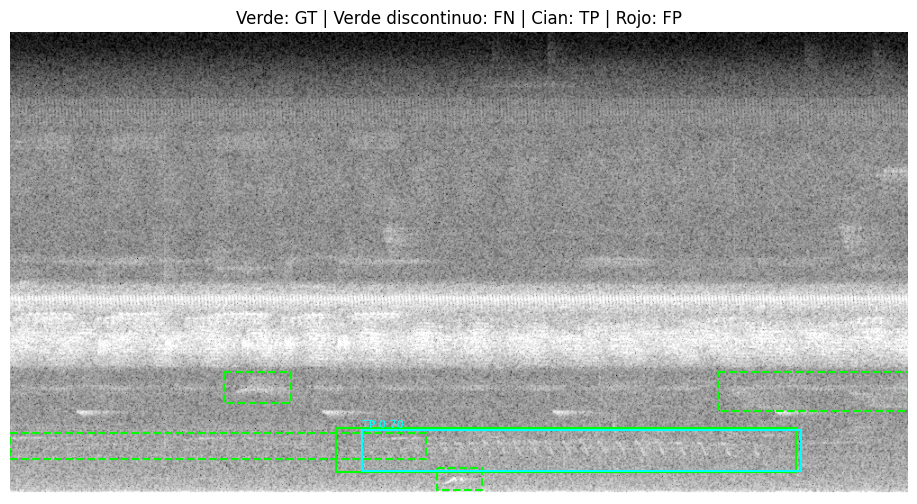

,t_min,t_max,f_min,f_max,score_detector,estado,iou_gt
0,1134.735,1138.648,820.795,2237.23,0.7,TP,0.876


Eventos reales no detectados (FN):


,event_id,t_min,t_max,f_min,f_max
0,Peru::12783,1135.4,1135.8,158.0,912.0
2,Peru::13077,1131.6,1135.3,1230.0,2142.0
3,Peru::13109,1137.9,1139.6,2896.0,4246.0
4,Peru::13127,1133.5,1134.1,3174.0,4246.0


In [22]:
predicciones = sistema.detector.predict([imagen_deteccion], threshold=CONF_MIN)
pred = predicciones[0]
cajas = np.asarray(pred.xyxy, dtype=np.float64).reshape(-1, 4)
scores = np.asarray(pred.confidence, dtype=np.float64).reshape(-1)
ancho, alto = imagen_deteccion.size

# Convertir coordenadas de imagen a tiempo y frecuencia.
tabla_todas = pd.DataFrame({
    "t_min": inicio_s + cajas[:, 0] / ancho * DURACION_VENTANA,
    "t_max": inicio_s + cajas[:, 2] / ancho * DURACION_VENTANA,
    "f_min": (1 - cajas[:, 3] / alto) * (FS / 2),
    "f_max": (1 - cajas[:, 1] / alto) * (FS / 2),
    "score_detector": scores
})

# Evaluamos únicamente las predicciones operativas.
pred_a = (tabla_todas.loc[tabla_todas.score_detector >= CONF_OPERATIVA].sort_values("score_detector", ascending=False).reset_index(drop=True))
gt_a = anotaciones_de(uid, inicio_s, inicio_s + DURACION_VENTANA)
pares_a = emparejar(pred_a, gt_a)
aciertos = {
    i: (j, iou)
    for i, j, iou in pares_a
}

gt_detectados = {
    j for _, j, _ in pares_a
}

pred_a["estado"] = ["TP" if i in aciertos else "FP" for i in range(len(pred_a))]
pred_a["iou_gt"] = [aciertos[i][1] if i in aciertos else np.nan for i in range(len(pred_a))]

# metricas de esta muestra
TP = len(pares_a)
FP = len(pred_a) - TP
FN = len(gt_a) - TP

precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
f1 = (2 * precision * recall / (precision + recall) if precision + recall else 0.0)

print("EXPERIMENTO A — RESULTADOS")
print(f"Anotaciones reales: {len(gt_a)}")
print(f"Predicciones evaluadas: {len(pred_a)}")
print(f"TP: {TP} | FP: {FP} | FN: {FN}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1: {f1:.4f}")


fig, ax = plt.subplots(figsize=(14, 6))
ax.imshow(imagen_deteccion)
ax.axis("off")

# Dibujar anotaciones reales en verde
for j, fila_gt in gt_a.iterrows():
    x0 = (fila_gt.t_min - inicio_s) / DURACION_VENTANA * ancho
    x1 = (fila_gt.t_max - inicio_s) / DURACION_VENTANA * ancho
    y0 = (1 - fila_gt.f_max / (FS / 2)) * alto
    y1 = (1 - fila_gt.f_min / (FS / 2)) * alto

    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, linewidth=1.5, edgecolor="lime", linestyle="-" if j in gt_detectados else "--"))

# Dibujar TP en cian y FP en rojo
for _, fila_pred in pred_a.head(20).iterrows():

    x0 = (fila_pred.t_min - inicio_s) / DURACION_VENTANA * ancho
    x1 = (fila_pred.t_max - inicio_s) / DURACION_VENTANA * ancho
    y0 = (1 - fila_pred.f_max / (FS / 2)) * alto
    y1 = (1 - fila_pred.f_min / (FS / 2)) * alto

    color = "cyan" if fila_pred.estado == "TP" else "red"

    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, linewidth=1.5, edgecolor=color))

    ax.text(x0, max(y0 - 2, 0), f"{fila_pred.estado} {fila_pred.score_detector:.2f}", color=color, fontsize=8)

ax.set_title(
    "Verde: GT | Verde discontinuo: FN | "
    "Cian: TP | Rojo: FP"
)

plt.show()

# Tabla de predicciones
if not pred_a.empty:
    display(pred_a[["t_min", "t_max", "f_min", "f_max", "score_detector", "estado", "iou_gt"]].head(20).round(3))

# Anotaciones que el detector no encontr0
if FN:
    print("Eventos reales no detectados (FN):")

    display(
        gt_a.loc[
            [j not in gt_detectados for j in range(len(gt_a))],
            ["event_id", "t_min", "t_max", "f_min", "f_max"]
        ].head(20).round(3)
    )
else:
  print("El detector no produjo candidatos en este segmento. Esto no es un error de ejecución.")

TP — Aciertos

FP — Falsas alarmas

FN — No detectados

Verde discontinuo: anotaciones reales que el detector no logró recuperar. Son los cuatro FN.

Cian: caja predicha por el detector que coincide con una anotación real. Es el único TP.

Verde continuo: anotación real que fue emparejada con la predicción cian. Puede quedar parcialmente oculta por esta.

Rojo: correspondería a predicciones incorrectas. No aparece ninguna porque FP = 0.

## Experimento B — Clasificador individual (Swin-T)

Utilizamos **un PNG independiente, ya preprocesado**, procedente del dataset público del clasificador. RF-DETR **no interviene**. Mostramos la clase real proporcionada en el manifiesto y la clase predicha. Una sola imagen sirve como prueba funcional, **no como medición de exactitud**.

100%|██████████| 1.67M/1.67M [00:00<00:00, 4.67MB/s]


Using Colab cache for faster access to the 'clasificador-aves-espectrogramas-v1' dataset.
Evento: Peru::16399
Etiqueta real: 20 | patagioenas plumbea
Predicción Swin-T: 20 | patagioenas plumbea
Confianza de la clase predicha: 0.651


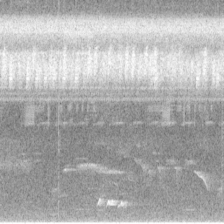

In [23]:
manifest = pd.read_csv(descargar_archivo(DATASET_CLASIFICADOR, "manifest_test.csv"), dtype={"event_id": str},)
columnas = {"event_id", "eligible_primary", "class_code", "archivo_tar", "ruta_png"}
assert columnas <= set(manifest), "Formato inesperado de manifest_test.csv"
elegible = manifest.eligible_primary.astype(str).str.lower().eq("true")
seleccion = manifest.loc[elegible].sort_values("event_id")
assert not seleccion.empty, "No hay espectrogramas elegibles para esta demostración"
fila_png = seleccion.sample(n=1).iloc[0]
ruta_relativa_png = f"{Path(str(fila_png.archivo_tar)).stem}/{str(fila_png.ruta_png).lstrip('/')}"
ruta_png = descargar_archivo(DATASET_CLASIFICADOR, ruta_relativa_png)

with Image.open(ruta_png) as archivo:
    imagen_cls = archivo.convert("RGB")

clases_predichas, probabilidades = sistema.clasificar_imagenes([imagen_cls])
clase_predicha = int(clases_predichas[0])
clase_real = int(fila_png.class_code)

print("Evento:", fila_png.event_id)
print("Etiqueta real:", clase_real, "|", sistema.codigos[clase_real])
print("Predicción Swin-T:", clase_predicha, "|", sistema.codigos[clase_predicha])
print(f"Confianza de la clase predicha: {probabilidades[0]:.3f}")
display(imagen_cls)

## Experimento C — Sistema integrado RF-DETR → Swin-T

Se ejecuta **exactamente** el método `predecir_audio()` exportado por el notebook 12: ventanas de ocho segundos con salto de cuatro, detección, NMS y clasificación de candidatos con confianza operativa ≥ 0,50. Se utiliza la misma grabación pública descargada anteriormente.

In [24]:
resultado = sistema.predecir_audio(ruta_audio, uid=uid, conf_min=CONF_MIN, conf_operativa=CONF_OPERATIVA)

print("Candidatos totales:", len(resultado))
print("Eventos clasificados:", int(resultado.pred_code.notna().sum()))

pred_c = (resultado.loc[resultado.score_detector >= CONF_OPERATIVA].sort_values("score_detector", ascending=False).reset_index(drop=True).copy())
gt_c = anotaciones_de(uid, 0, float(info.duration))
pares_c = emparejar(pred_c, gt_c)
aciertos_c = {
    i: (j, iou)
    for i, j, iou in pares_c
}

gt_detectados_c = {
    j for _, j, _ in pares_c
}

TP_C = len(pares_c)
FP_C = len(pred_c) - TP_C
FN_C = len(gt_c) - TP_C

pred_c["estado_detector"] = ["TP" if i in aciertos_c else "FP" for i in range(len(pred_c))]
pred_c["iou_gt"] = [aciertos_c[i][1] if i in aciertos_c else np.nan for i in range(len(pred_c))]
pred_c["event_id_real"] = [
    str(gt_c.iloc[aciertos_c[i][0]].event_id)
    if i in aciertos_c else None
    for i in range(len(pred_c))
]

pred_c["especie_real"] = None
pred_c["estado_especie"] = "SIN_GT"

for i in range(len(pred_c)):

    # Si la detección es FP, no hay una especie real emparejada
    if i not in aciertos_c:
        continue

    indice_gt, iou = aciertos_c[i]

    event_id = str(gt_c.iloc[indice_gt].event_id)

    clase_real = ETIQUETAS_REALES.get(event_id)

    if clase_real is None:
        pred_c.at[i, "estado_especie"] = "NO_EVALUABLE"
        continue

    pred_c.at[i, "especie_real"] = sistema.codigos.get(
        int(clase_real),
        f"CODIGO_{clase_real}"
    )

    clase_predicha = pred_c.at[i, "pred_code"]

    if pd.isna(clase_predicha):
        pred_c.at[i, "estado_especie"] = "SIN_CLASIFICAR"

    elif int(clase_predicha) == int(clase_real):
        pred_c.at[i, "estado_especie"] = "CORRECTA"

    else:
        pred_c.at[i, "estado_especie"] = "INCORRECTA"



precision_c = (TP_C / (TP_C + FP_C) if TP_C + FP_C else 0.0)
recall_c = (TP_C / (TP_C + FN_C) if TP_C + FN_C else 0.0)
correctas = int(pred_c.estado_especie.eq("CORRECTA").sum())
evaluables = int(pred_c.estado_especie.isin(["CORRECTA", "INCORRECTA"]).sum())

print("\nEXPERIMENTO C — DETECTOR")
print(f"Anotaciones reales: {len(gt_c)}")
print(f"TP: {TP_C} | FP: {FP_C} | FN: {FN_C}")
print(f"Precision: {precision_c:.4f}")
print(f"Recall: {recall_c:.4f}")

print("\nEXPERIMENTO C — CLASIFICADOR")
print(f"Especies correctas: {correctas}")
print(f"Eventos detectados con etiqueta evaluable: {evaluables}")

if evaluables:
    print(f"Accuracy condicional: {correctas / evaluables:.4f}")
else:
    print("No hay eventos emparejados con especie evaluable.")

columnas_resultado = ["t_min", "t_max", "score_detector", "estado_detector", "iou_gt", "event_id_real", "especie_real", "pred_label", "score_clasificador", "estado_especie"]

if not pred_c.empty:
    display(
        pred_c[columnas_resultado]
        .head(20)
        .round(3)
    )
else:
    print("No hubo detecciones que superaran el umbral operativo.")

# Mostrar anotaciones no detectadas
faltantes = gt_c.loc[
    [j not in gt_detectados_c for j in range(len(gt_c))],
    ["event_id", "t_min", "t_max", "f_min", "f_max"]
]

if not faltantes.empty:
    print(f"\nEventos reales no detectados: {len(faltantes)}")
    display(faltantes.head(20).round(3))

Candidatos totales: 37011
Eventos clasificados: 1472

EXPERIMENTO C — DETECTOR
Anotaciones reales: 645
TP: 192 | FP: 1280 | FN: 453
Precision: 0.1304
Recall: 0.2977

EXPERIMENTO C — CLASIFICADOR
Especies correctas: 98
Eventos detectados con etiqueta evaluable: 105
Accuracy condicional: 0.9333


,t_min,t_max,score_detector,estado_detector,iou_gt,event_id_real,especie_real,pred_label,score_clasificador,estado_especie
0,2452.016,2460.000,0.952,FP,NaN,None,None,campylorhynchus turdinus,0.738,SIN_GT
1,2008.011,2016.000,0.951,FP,NaN,None,None,campylorhynchus turdinus,0.954,SIN_GT
2,2448.000,2456.000,0.950,FP,NaN,None,None,OTHER_SPECIES,0.281,SIN_GT
3,2272.007,2280.000,0.950,FP,NaN,None,None,campylorhynchus turdinus,0.642,SIN_GT
4,2216.008,2224.000,0.950,FP,NaN,None,None,campylorhynchus turdinus,0.381,SIN_GT
5,2156.011,2163.999,0.949,FP,NaN,None,None,momotus momota,0.540,SIN_GT
6,2760.009,2768.000,0.949,FP,NaN,None,None,OTHER_SPECIES,0.851,SIN_GT
7,2192.016,2200.000,0.948,FP,NaN,None,None,campylorhynchus turdinus,0.936,SIN_GT
8,2128.021,2136.000,0.947,FP,NaN,None,None,momotus momota,0.933,SIN_GT
9,2856.001,2864.000,0.947,FP,NaN,None,None,campylorhynchus turdinus,0.819,SIN_GT



Eventos reales no detectados: 453


,event_id,t_min,t_max,f_min,f_max
0,Peru::12668,34.2,35.1,277.0,1388.0
1,Peru::12669,75.9,83.6,595.0,1071.0
2,Peru::12670,221.8,227.4,555.0,1031.0
3,Peru::12671,260.8,261.2,555.0,1031.0
4,Peru::12672,372.9,390.1,436.0,1507.0
5,Peru::12673,390.1,391.4,992.0,1587.0
6,Peru::12674,407.6,435.6,515.0,1388.0
7,Peru::12675,420.1,435.5,1071.0,1785.0
8,Peru::12676,452.1,455.1,595.0,1150.0
9,Peru::12677,461.1,464.7,754.0,1388.0
